# Clasificación. Parte II - Clasificación multiclase.

Seguimos con un sistemas de aprendizaje automático **supervisado** de **clasificación**.

Mientras que un clasificador binario distingue dos clase, un **clasificador multiclase** (clasificador multinomial) puede distinguir más de dos clases.

Continuamos trabajando con el dataset **MNIST** (Modified National Institute of Standards and Technology).

En este caso, nuestro objetivo es crear un modelo que sea capaz de decir a qué dígito se corresponde una imagen determinada.

Hay varias estrategias posibles para clasificar los dígitos del 0 al 9:

* <u>Crear un clasificador para cada dígito</u>, aplicarlos todos y quedarnos con el resultado que nos interesa. Este método se llama **OvR** (*one versus the rest*) o también **OvA** (*one versus all*). Por ejemplo, si el dígito es un 7, el clasificador de 0/no 0 dirá que no es un 0, el 1/no 1 dirá que no es un 1, ... y el de 7/no 7 dirá que es un 7.

* <u>Crear un clasificador para cada par de dígitos</u>. Uno que distinga entre 0 y 1, otro entre 0 y 2, otro entre 0 y 3, ... otro entre 1 y 2, otro entre 1 y 3... Si hay $N$ clases, necesitamos $N \times (N - 1) / 2$ clasificadores. En el caso que nos ocupa, tendríamos que crear 45 clasificadores. A cada imagen habría que pasarle los 45 clasificadores y puntuar cada resultado. Escogeríamos la clase que mejor se haya comportado, igual que en una liga de fútbol en la que se enfrenta cada equipo con todos los demás. Esta técnica se llama **OvO** (*one vs one*). Por ejemplo, si el dígito es un 8, al aplicar el clasificador 0/8, saldrá el 8 y se le dará un punto, al aplicar el clasificador 1/8 saldrá el 8 y se le dará otro punto, etc. Al final, la clase 8 tendrá más puntos.

* <u>Crear un clasificador multiclase</u>. Hay algoritmos, como por ejemplo el *k-Nearest Neighbours*, que trabajan bien detectando de forma nativa varias clases diferentes.

## Importaciones

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

## Carga de datos

In [3]:
from sklearn.datasets import fetch_openml
mnist = fetch_openml("mnist_784", version=1)

## Extracción de la matriz de características y del target

In [4]:
X = mnist["data"]
y = mnist["target"]
y = y.to_numpy()
y = y.astype(np.uint8)

## Creación del conjunto de datos de entrenamiento y prueba

In [5]:
X_train, X_test, y_train, y_test = X[:60000], X[60000:], y[:60000], y[60000:]

## Extracción de algunos números de prueba

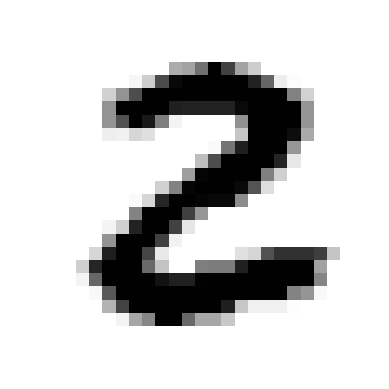

In [6]:
example_digit1 = X.loc[25, :].to_numpy()
example_digit1_image = example_digit1.reshape(28, 28)
plt.imshow(example_digit1_image, cmap="binary")
plt.axis("off")
plt.show()

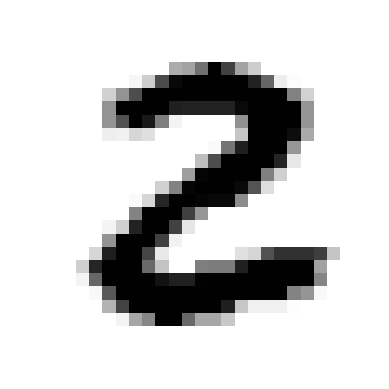

In [7]:
example_digit2 = X.loc[26, :].to_numpy()
example_digit2_image = example_digit1.reshape(28, 28)
plt.imshow(example_digit2_image, cmap="binary")
plt.axis("off")
plt.show()

## Creación del clasificador multiclase a partir de la técnica **0v0**

Vamos a usar el algoritmo SVM (Support Vector Machine) que intrínsecamente es un clasificador binario.

Scikit Learn es capaz de detectar que queremos hacer un clasificador multiclase y "por debajo" usa la técnica 0v0, es decir, crea 45 clasificadores y mira que dígito gana la liga.

In [8]:
from sklearn.svm import SVC

model_svc = SVC(random_state=18)
model_svc.fit(X_train, y_train)

SVC(random_state=18)

In [9]:
# Digitos de ejemplo

model_svc.predict([example_digit1, example_digit2])

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but SVC was fitted with feature names
  warnings.warn(


array([2, 4], dtype=uint8)

In [10]:
# Muestra las clases que detecta el modelo

model_svc.classes_

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9], dtype=uint8)

In [11]:
# Puntuación de cada una de las clases para la imagen example_digit1
# La clase correspondiente al 2 debería tener la máxima puntuación

model_svc.decision_function([example_digit1])

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but SVC was fitted with feature names
  warnings.warn(


array([[ 4.92505076,  3.74597077,  9.31442812,  8.30989605, -0.3123735 ,
         5.78209525,  2.71797624,  0.69243018,  7.3117808 ,  1.71052032]])

In [12]:
model_svc.decision_function([example_digit2])

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but SVC was fitted with feature names
  warnings.warn(


array([[-0.30561611,  2.71904625,  2.72182152,  6.1750562 ,  9.31070254,
         2.78903166,  0.70489991,  7.28077821,  5.12715056,  8.30325366]])

## Rendimiento del modelo (SVC)

### Aciertos y fallos

Usamos los datos de prueba para hacer predicciones y comprobar si son correctas.

In [13]:
y_test_pred = model_svc.predict(X_test)

success = (y_test_pred == y_test)

aciertos = success[success == True].size
fallos = success[success == False].size

print("Aciertos: ", aciertos)
print("Fallos: ", fallos)
print("Precisión: ", (aciertos / (aciertos + fallos)) * 100, "%")

Aciertos:  9792
Fallos:  208
Precisión:  97.92 %


Hemos obtenido casi un 98% de aciertos.

### Validación cruzada



In [ ]:
# from sklearn.model_selection import cross_val_score

# cross_val_score(model_svc, X, y, cv=3)

Más del 0.97 en cada caso.

## Matriz de confusión

In [14]:
from sklearn.metrics import confusion_matrix

conf_matrix = confusion_matrix(y_test, y_test_pred)
conf_matrix

array([[ 973,    0,    1,    0,    0,    2,    1,    1,    2,    0],
       [   0, 1126,    3,    1,    0,    1,    1,    1,    2,    0],
       [   6,    1, 1006,    2,    1,    0,    2,    7,    6,    1],
       [   0,    0,    2,  995,    0,    2,    0,    5,    5,    1],
       [   0,    0,    5,    0,  961,    0,    3,    0,    2,   11],
       [   2,    0,    0,    9,    0,  871,    4,    1,    4,    1],
       [   6,    2,    0,    0,    2,    3,  944,    0,    1,    0],
       [   0,    6,   11,    1,    1,    0,    0,  996,    2,   11],
       [   3,    0,    2,    6,    3,    2,    2,    3,  950,    3],
       [   3,    4,    1,    7,   10,    2,    1,    7,    4,  970]])

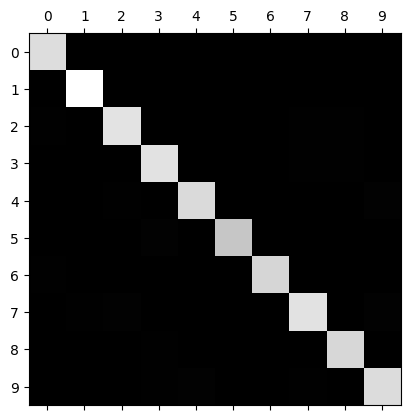

In [15]:
# Representación gráfica de la matriz de confusión

plt.matshow(conf_matrix, cmap=plt.cm.gray)
plt.xticks(np.arange(10))
plt.yticks(np.arange(10))
plt.show()

## Creación de un clasificador multiclase con el algoritmo **K-Nearest Neighbours**

Vamos a usar el algoritmo **K-Nearest Neighbours** (k-vecinos más cercanos) que es, de forma nativa, un clasificador multiclase.

In [16]:
from sklearn.neighbors import KNeighborsClassifier

model_knn = KNeighborsClassifier()
model_knn.fit(X_train, y_train)

KNeighborsClassifier()

In [17]:
model_knn.predict([example_digit1, example_digit2])

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(


array([2, 4], dtype=uint8)

In [18]:
y_test_pred = model_knn.predict(X_test)

success = (y_test_pred == y_test)

aciertos = success[success == True].size
fallos = success[success == False].size

print("Aciertos: ", aciertos)
print("Fallos: ", fallos)
print("Precisión: ", (aciertos / (aciertos + fallos)) * 100, "%")

Aciertos:  9688
Fallos:  312
Precisión:  96.88 %


In [ ]:
# cross_val_score(model_knn, X, y, cv=3)

## Prueba con imágenes reales

In [21]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


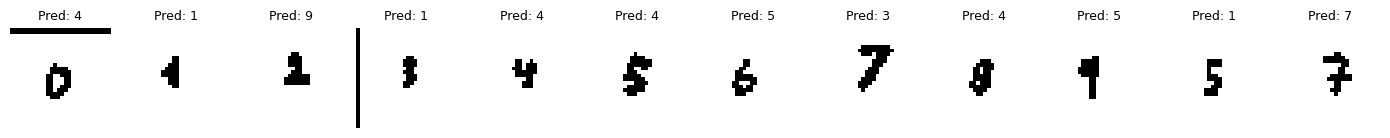

In [35]:
# Carga y decodificación robusta de imágenes reales usando PIL y binarización
import cv2
import os
import pandas as pd
import numpy as np
from PIL import Image

# Ajustamos los subplots para mostrar 12 imágenes
fig, ax = plt.subplots(1, 12, figsize=(14, 3))

for i in range(12):
  # Carga la imagen
  image_name = f"/content/drive/MyDrive/numeros_manuscritos/numero{i}.jpg"

  # Verificamos si el archivo existe antes de cargarlo
  if not os.path.exists(image_name):
    print(f"Advertencia: No se encontró el archivo: {image_name}")
    ax[i].text(0.5, 0.5, 'Sin imagen', ha='center', va='center')
    ax[i].axis("off")
    continue

  try:
    # Usamos PIL para abrir la imagen (evita fallos de lectura de OpenCV con ciertos JPGs)
    pil_img = Image.open(image_name).convert("L")
    image_raw = np.array(pil_img)
  except Exception as e:
    print(f"Error al leer {image_name} con PIL: {e}")
    ax[i].text(0.5, 0.5, 'Error lectura', ha='center', va='center')
    ax[i].axis("off")
    continue

  # Redimensiona a 28x28 píxeles
  image_resized = cv2.resize(image_raw, (28, 28), interpolation=cv2.INTER_AREA)

  # Invierte colores
  image_inverted = 255 - image_resized

  # Binarización para limpiar el ruido del papel y mejorar la predicción
  _, image_thresholded = cv2.threshold(image_inverted, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

  # Aplana la imagen para el modelo
  real_image_for_test = image_thresholded.flatten()

  # Convertimos a DataFrame con nombres de columnas válidos
  df_input = pd.DataFrame([real_image_for_test], columns=X_train.columns)

  # Hace la predicción
  prediction = model_svc.predict(df_input)

  # Muestra la predicción en la imagen
  ax[i].set_title(f"Pred: {prediction[0]}", fontsize=9)
  ax[i].imshow(image_thresholded, cmap="binary")
  ax[i].axis("off")

plt.tight_layout()
plt.show()